# Fairness Analysis — Denials

Same models and groups as `Fairness_Analysis.ipynb`, but charts show **denial rates** instead of approval rates.

Why denials: the data is heavily skewed toward approvals (~75%), so denial gaps are often clearer for fairness.

- **True denial rate** = share actually denied in the data  
- **Model denial rate** = share the model would deny (at threshold 0.5)  
- **Gap (group B − group A):** positive means group B is denied more often


In [1]:
import sys
sys.path.append('../scripts')
import os
os.environ.setdefault('KERAS_BACKEND', 'torch')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_test = pd.read_csv('../data/features/X_test_prep.csv', index_col='row_id')
y_test = pd.read_csv('../data/features/y_test.csv', index_col='row_id')['is_approved']
protected = pd.read_csv('../data/features/protected_test.csv', index_col='row_id')

# Load sklearn/xgboost BEFORE keras
MODELS = {
  'Logistic Regression': joblib.load('../data/models/logistic_regression_model.joblib'),
  'Decision Tree': joblib.load('../data/models/decision_tree_model.joblib'),
  'RF Balanced': joblib.load('../data/models/random_forest_balanced.joblib'),
  'RF Imbalanced': joblib.load('../data/models/random_forest_classifier_imbalanced.joblib'),
  'RF Protected*': joblib.load('../data/models/random_forest_balanced_protected.joblib'),
  'XGBoost': joblib.load('../data/models/xgboost_model.joblib'),
}
import keras
from fairness_eval import results_by_group
MODELS['Neural Network'] = keras.models.load_model('../data/models/neural_network_model.keras')
print('Loaded', len(MODELS), 'models')


Loaded 7 models


In [2]:
def run_all(group):
  return {name: results_by_group(model, X_test, y_test, group) for name, model in MODELS.items()}

def denial_compare(tables, group_col, group_a, group_b, title):
  """True + model denial rates for two groups across all models."""
  def val(table, name, kind):
    row = table.loc[table[group_col] == name].iloc[0]
    if kind == 'true':
      return float(1 - row['approval_rate'])
    return float(1 - row['predicted_approval_rate'])

  first = next(iter(tables.values()))
  labels = ['True denial rate\n(in the data)'] + [f'{name}\ndenial rate' for name in tables]
  a_vals = [val(first, group_a, 'true')]
  b_vals = [val(first, group_b, 'true')]
  for table in tables.values():
    a_vals.append(val(table, group_a, 'pred'))
    b_vals.append(val(table, group_b, 'pred'))

  x = np.arange(len(labels))
  width = 0.38
  fig, ax = plt.subplots(figsize=(max(11, 1.8 * len(labels)), 5.5))
  bars_a = ax.bar(x - width/2, a_vals, width, label=group_a, color='#4C78A8')
  bars_b = ax.bar(x + width/2, b_vals, width, label=group_b, color='#F58518')
  for bars in (bars_a, bars_b):
    for bar in bars:
      h = bar.get_height()
      ax.text(bar.get_x()+bar.get_width()/2, h+0.015, f'{h:.0%}',
              ha='center', va='bottom', fontsize=9, fontweight='bold')
  for i, (va, vb) in enumerate(zip(a_vals, b_vals)):
    ax.text(i, max(va, vb)+0.09, f'gap {vb-va:+.0%}', ha='center', fontsize=9, color='#B35C00')
  ax.set_ylim(0, 1.2)
  ax.set_ylabel('Denial rate')
  ax.set_xticks(x)
  ax.set_xticklabels(labels, fontsize=8)
  ax.set_title(title, fontsize=14, fontweight='bold')
  ax.legend(loc='upper right')
  plt.tight_layout()
  plt.show()


## Race — Black vs White (denial rates)


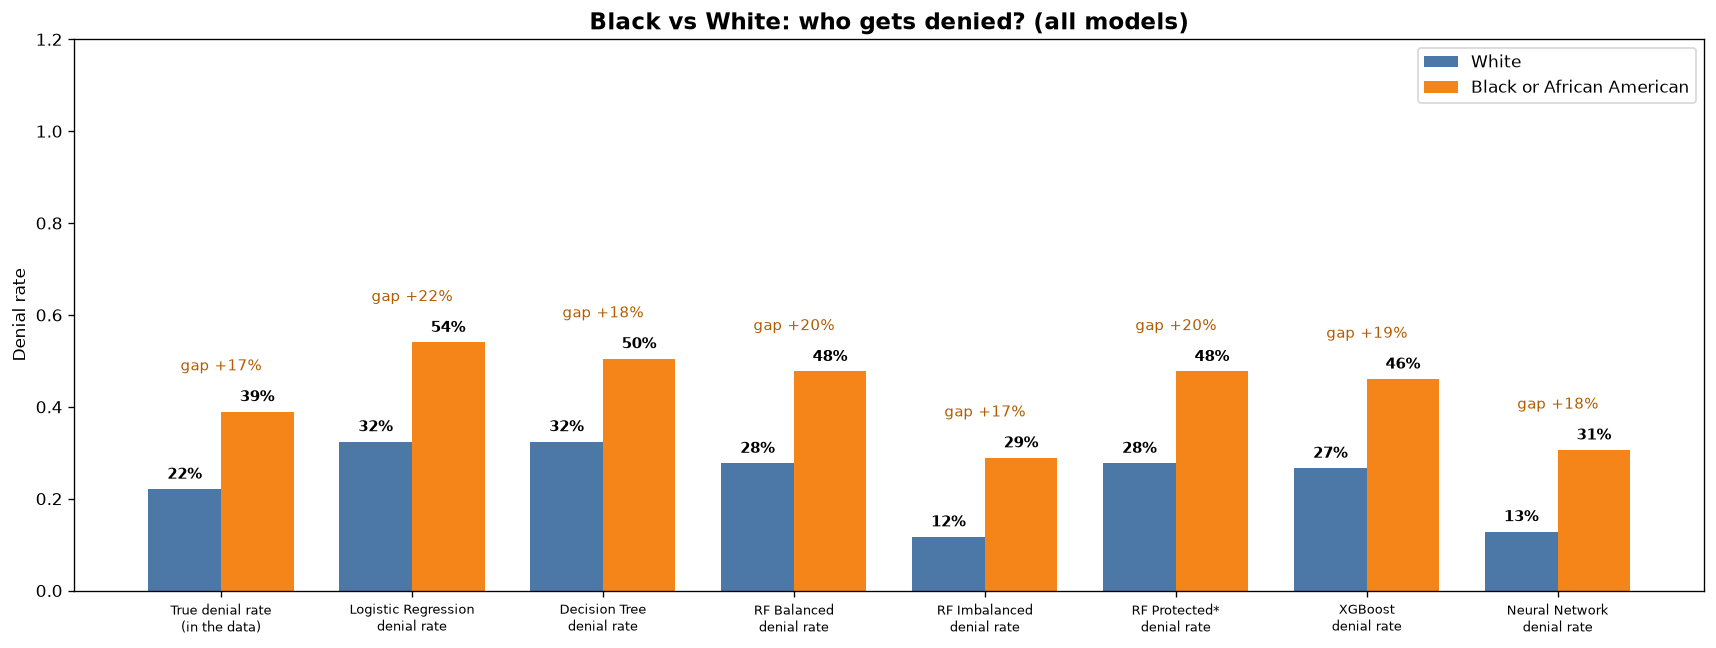

In [3]:
race_tables = run_all(protected['applicant_race_1'])
denial_compare(
  race_tables, 'applicant_race_1',
  'White', 'Black or African American',
  'Black vs White: who gets denied? (all models)',
)


## Sex — Female vs Male (denial rates)


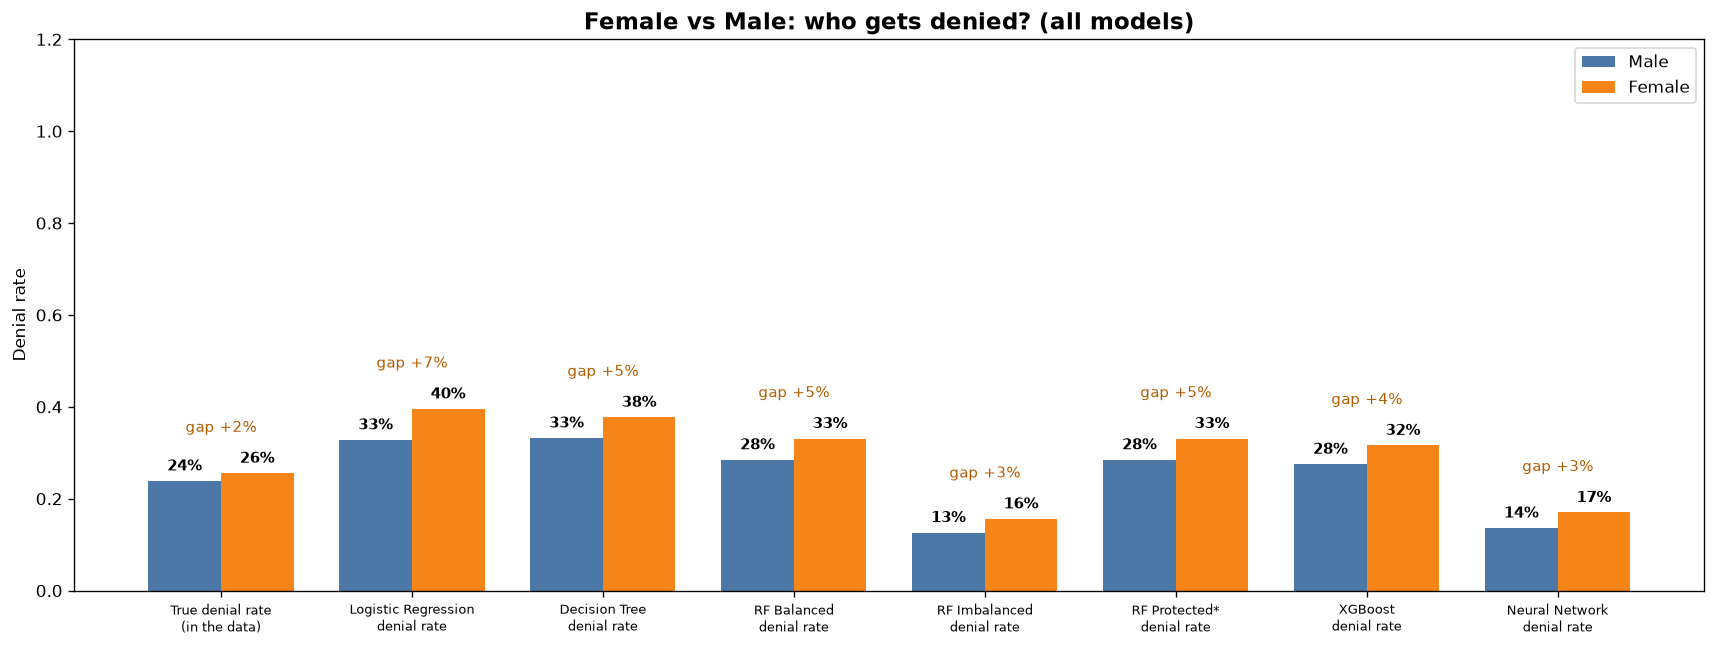

In [4]:
sex_tables = run_all(protected['applicant_sex'])
denial_compare(
  sex_tables, 'applicant_sex',
  'Male', 'Female',
  'Female vs Male: who gets denied? (all models)',
)


## Ethnicity — Hispanic vs Not Hispanic (denial rates)


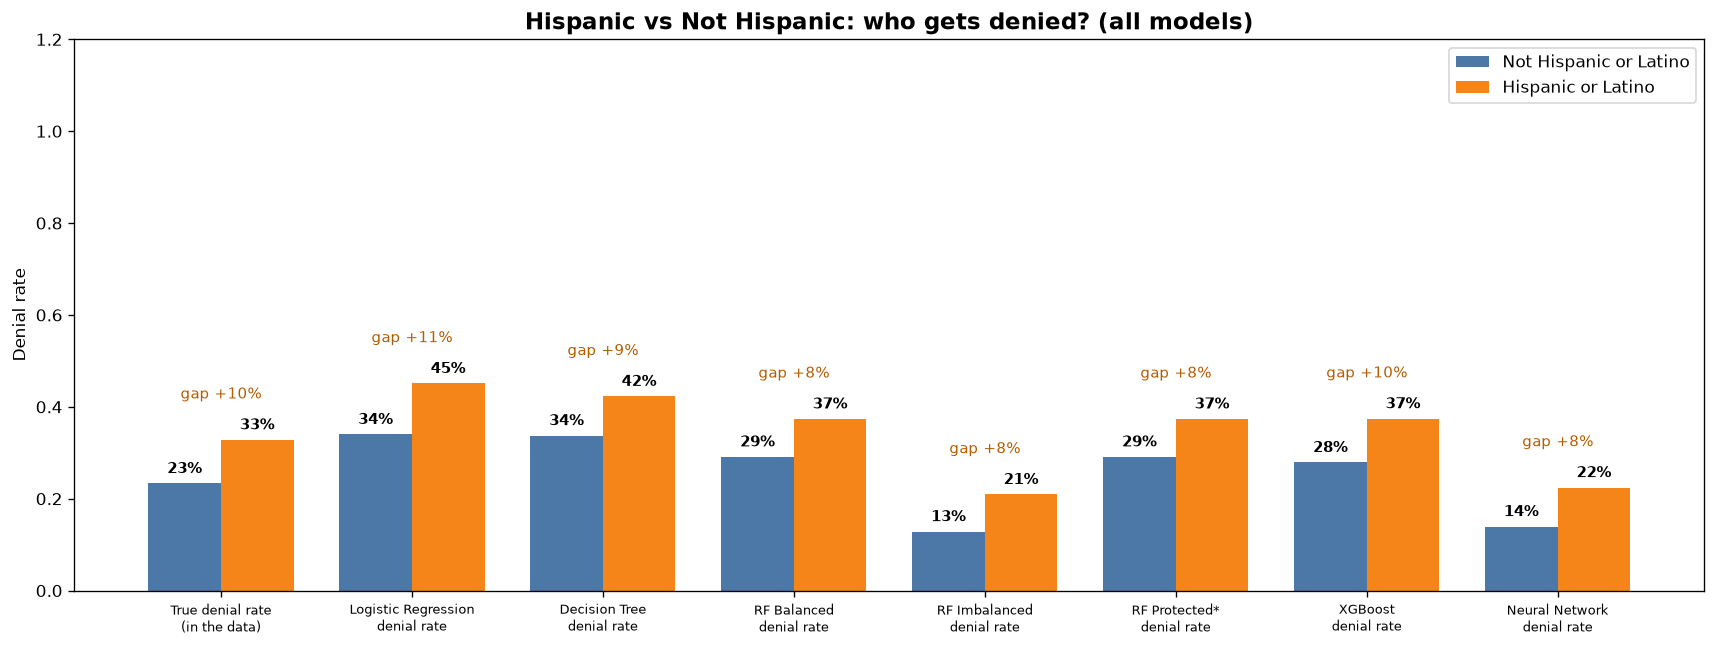

In [5]:
eth_tables = run_all(protected['applicant_ethnicity'])
denial_compare(
  eth_tables, 'applicant_ethnicity',
  'Not Hispanic or Latino', 'Hispanic or Latino',
  'Hispanic vs Not Hispanic: who gets denied? (all models)',
)


## Model scorecard — denials focus

Performance plus Black−White **denial** gaps (positive = Black denied more often).


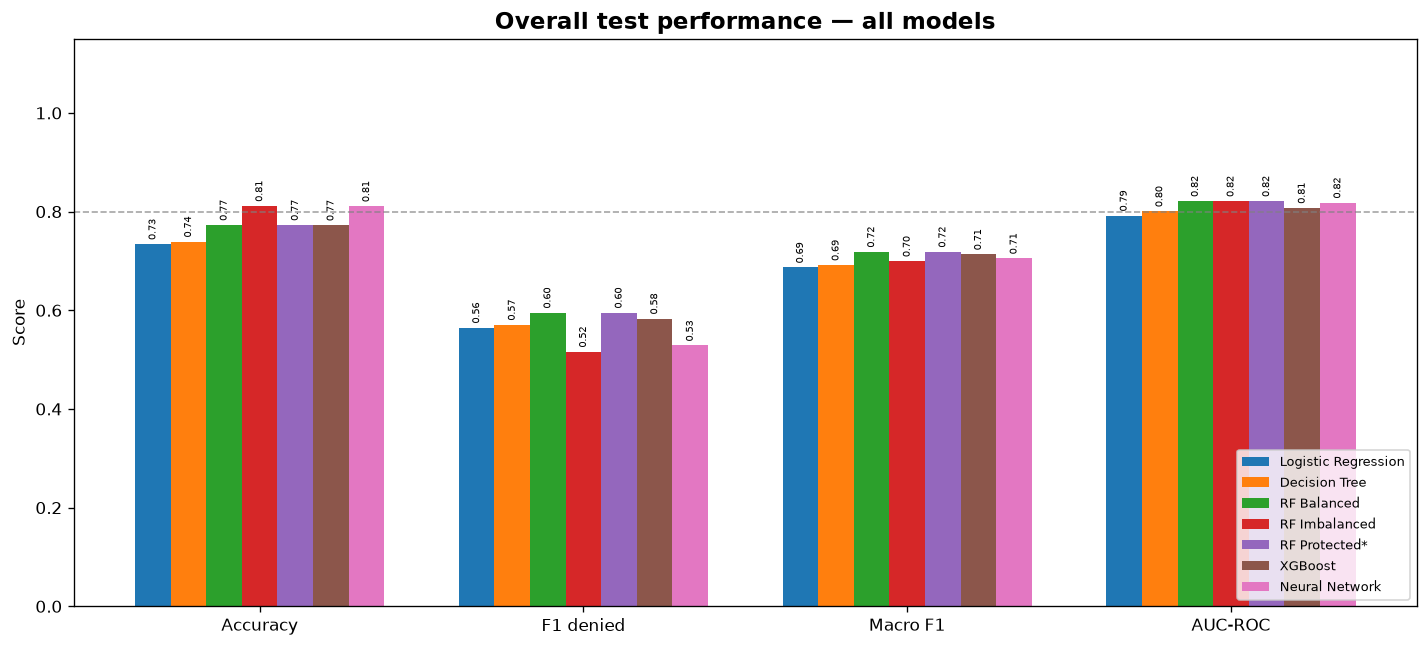

In [6]:
# Performance chart (denial-relevant metrics highlighted)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from fairness_eval import _approval_probability

rows = []
for name, model in MODELS.items():
  scores = _approval_probability(model, X_test)
  pred = (scores >= 0.5).astype(int)
  w = race_tables[name].loc[race_tables[name]['applicant_race_1'] == 'White'].iloc[0]
  b = race_tables[name].loc[race_tables[name]['applicant_race_1'] == 'Black or African American'].iloc[0]
  rows.append({
    'model': name,
    'accuracy': accuracy_score(y_test, pred),
    'f1_denied': f1_score(y_test, pred, pos_label=0),
    'macro_f1': f1_score(y_test, pred, average='macro'),
    'auc_roc': roc_auc_score(y_test, scores),
    'true_denial_gap': (1 - b['approval_rate']) - (1 - w['approval_rate']),
    'pred_denial_gap': (1 - b['predicted_approval_rate']) - (1 - w['predicted_approval_rate']),
  })
scorecard = pd.DataFrame(rows)

perf_cols = ['accuracy', 'f1_denied', 'macro_f1', 'auc_roc']
perf_labels = ['Accuracy', 'F1 denied', 'Macro F1', 'AUC-ROC']
x = np.arange(len(perf_labels))
width = 0.11
fig, ax = plt.subplots(figsize=(12, 5.5))
colors = plt.cm.tab10.colors
for i, (_, row) in enumerate(scorecard.iterrows()):
  vals = [row[c] for c in perf_cols]
  bars = ax.bar(x + (i - 3) * width, vals, width, label=row['model'], color=colors[i])
  for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.008, f'{v:.2f}',
            ha='center', va='bottom', fontsize=6, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(perf_labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title('Overall test performance — all models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.axhline(0.80, color='gray', ls='--', lw=1, alpha=0.7)
plt.tight_layout()
plt.show()


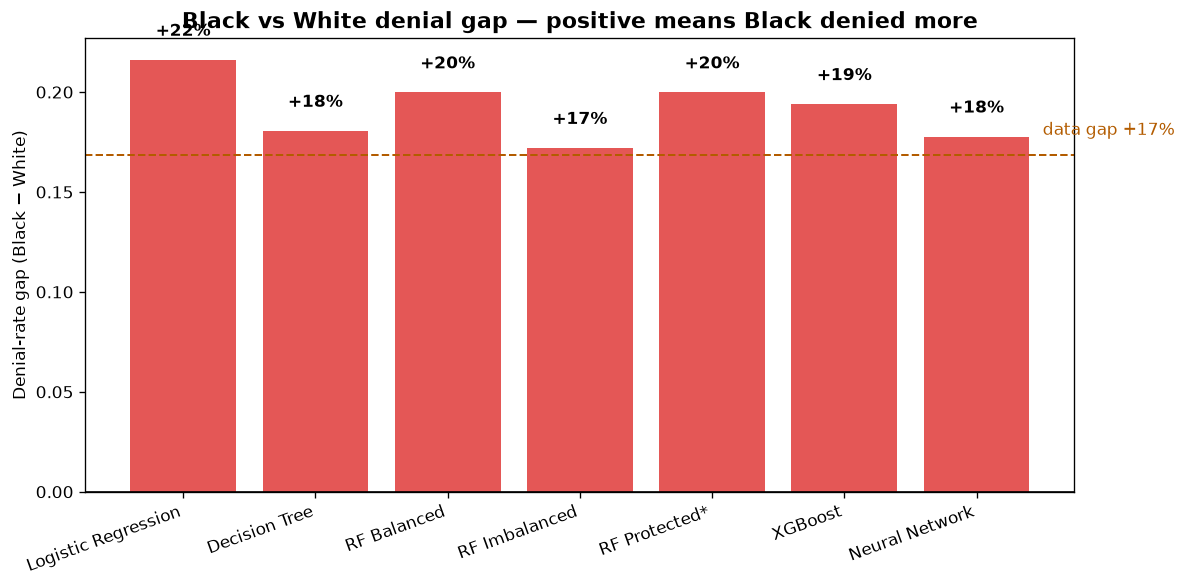

Positive gap = Black applicants denied more often than White.
Dashed line = gap already in the data. Models at/near that line are not widening denial disparity.


In [7]:
# Black-White denial gap by model
x = np.arange(len(scorecard))
vals = scorecard['pred_denial_gap'].to_numpy()
fig, ax = plt.subplots(figsize=(10, 5))
colors_bar = ['#E45756' if v > 0 else '#54A24B' for v in vals]
bars = ax.bar(x, vals, color=colors_bar)
true_gap = scorecard['true_denial_gap'].iloc[0]
ax.axhline(0, color='black', lw=1)
ax.axhline(true_gap, color='#B35C00', ls='--', lw=1.2)
ax.text(len(x) - 0.5, true_gap + 0.01, f'data gap {true_gap:+.0%}', color='#B35C00', fontsize=10)
for bar, v in zip(bars, vals):
  ax.text(bar.get_x() + bar.get_width()/2, v + 0.01 if v >= 0 else v - 0.02, f'{v:+.0%}',
          ha='center', va='bottom' if v >= 0 else 'top', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scorecard['model'], rotation=20, ha='right')
ax.set_ylabel('Denial-rate gap (Black − White)')
ax.set_title('Black vs White denial gap — positive means Black denied more', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Positive gap = Black applicants denied more often than White.')
print('Dashed line = gap already in the data.')
